In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from matplotlib import pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense



In [2]:
df = pd.read_csv("laptop_data_cleaned.csv")
df.head()

,Company,TypeName,Ram,Weight,Price,TouchScreen,Ips,Ppi,Cpu_brand,HDD,SSD,Gpu_brand,Os
0,Apple,Ultrabook,8,1.37,11.175755,0,1,226.983005,Intel Core i5,0,128,Intel,Mac
1,Apple,Ultrabook,8,1.34,10.776777,0,0,127.677940,Intel Core i5,0,0,Intel,Mac
2,HP,Notebook,8,1.86,10.329931,0,0,141.211998,Intel Core i5,0,256,Intel,Others
3,Apple,Ultrabook,16,1.83,11.814476,0,1,220.534624,Intel Core i7,0,512,AMD,Mac
4,Apple,Ultrabook,8,1.37,11.473101,0,1,226.983005,Intel Core i5,0,256,Intel,Mac


In [3]:
df.drop_duplicates(inplace=True)

In [4]:
# encoding the categorical data :
label = LabelEncoder()
df["encoded_company"] = label.fit_transform(df["Company"])
var1 = dict(zip(df["encoded_company"],df["Company"]))
print(var1)

df["encoded_typename"] = label.fit_transform(df["TypeName"])
var2 = dict(zip(df["TypeName"],df["encoded_typename"]))
print(var2)

df["encoded_cpu"] = label.fit_transform(df["Cpu_brand"])
var3 = dict(zip(df["Cpu_brand"],df["encoded_cpu"]))
print(var3)

df["encoded_Gpu"] = label.fit_transform(df["Gpu_brand"])
var4 = dict(zip(df["Gpu_brand"],df["encoded_Gpu"]))
print(var4)

df["encoded_os"] = label.fit_transform(df["Os"])
var5 = dict(zip(df["Os"],df["encoded_os"]))
print(var5)

{1: 'Apple', 7: 'HP', 0: 'Acer', 2: 'Asus', 4: 'Dell', 10: 'Lenovo', 3: 'Chuwi', 11: 'MSI', 13: 'Microsoft', 16: 'Toshiba', 8: 'Huawei', 18: 'Xiaomi', 17: 'Vero', 14: 'Razer', 12: 'Mediacom', 15: 'Samsung', 6: 'Google', 5: 'Fujitsu', 9: 'LG'}
{'Ultrabook': 4, 'Notebook': 3, 'Netbook': 2, 'Gaming': 1, '2 in 1 Convertible': 0, 'Workstation': 5}
{'Intel Core i5': 2, 'Intel Core i7': 3, 'AMD Processor': 0, 'Intel Core i3': 1, 'Other Intel Processor': 4}
{'Intel': 1, 'AMD': 0, 'Nvidia': 2}
{'Mac': 0, 'Others': 1, 'Windows': 2}


In [5]:
# droping the categorical columns:
df.drop(columns=["Company","TypeName","Cpu_brand","Gpu_brand","Os"],inplace=True)
df.head()

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,encoded_company,encoded_typename,encoded_cpu,encoded_Gpu,encoded_os
0,8,1.37,11.175755,0,1,226.983005,0,128,1,4,2,1,0
1,8,1.34,10.776777,0,0,127.677940,0,0,1,4,2,1,0
2,8,1.86,10.329931,0,0,141.211998,0,256,7,3,2,1,1
3,16,1.83,11.814476,0,1,220.534624,0,512,1,4,3,0,0
4,8,1.37,11.473101,0,1,226.983005,0,256,1,4,2,1,0


In [6]:
#feature selection:
x = df[["Ram","Weight","TouchScreen","Ips","Ppi","HDD","SSD","encoded_company","encoded_typename","encoded_cpu","encoded_Gpu","encoded_os"]]
y = df["Price"]

In [7]:
#splitting the data:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state =42)

In [8]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [13]:

# ann architecture:
model = Sequential()

#input layer:
model.add(Dense(512,activation="sigmoid",input_dim=12))

#hidden layer:
model.add(Dense(256,activation="relu"))

model.add(Dense(128,activation="relu"))

model.add(Dense(64,activation="relu"))

#output layer:
model.add(Dense(1,activation="linear"))

model.summary()

c:\Users\Anushkha Bhagra\Downloads\deep learning\ANN\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 512)            │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 179,201 (700.00 KB)

 Trainable params: 179,201 (700.00 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:

#model compile:
model.compile(optimizer="adam",loss= "mae", metrics= ["r2_score"])

In [16]:
history = model.fit(x_train_scaled,y_train,batch_size= 32,epochs=50,validation_split=0.2,verbose=1)

Epoch 1/50


26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 3.5184 - r2_score: -57.2944 - val_loss: 0.9174 - val_r2_score: -2.2607
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.5176 - r2_score: -0.1016 - val_loss: 0.3057 - val_r2_score: 0.5353
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3270 - r2_score: 0.5599 - val_loss: 0.3164 - val_r2_score: 0.5580
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3256 - r2_score: 0.5714 - val_loss: 0.3538 - val_r2_score: 0.4126
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3643 - r2_score: 0.4632 - val_loss: 0.4458 - val_r2_score: 0.2033
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3208 - r2_score: 0.5713 - val_loss: 0.2937 - val_r2_score: 0.6026
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3345 - r2_score: 0.5428 - val_loss: 0.5586 - val_r2_score: -0.1872
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4326 - r2_score: 0.2719 - val_loss: 0.3099 - val_r2_score: 0.58

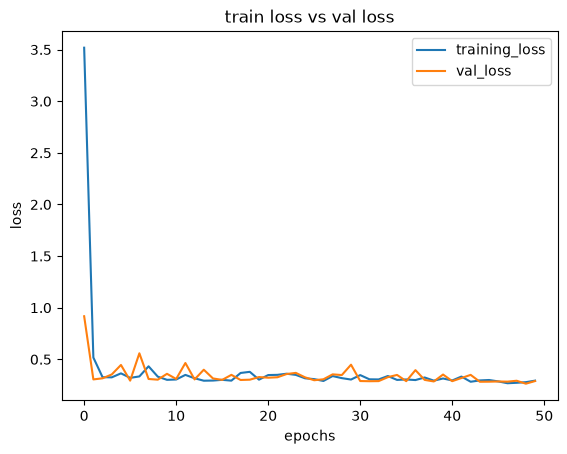

In [17]:
#plot the graphs:
plt.plot(history.history["loss"],label="training_loss")
plt.plot(history.history["val_loss"],label="val_loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("train loss vs val loss")
plt.legend()
plt.show()

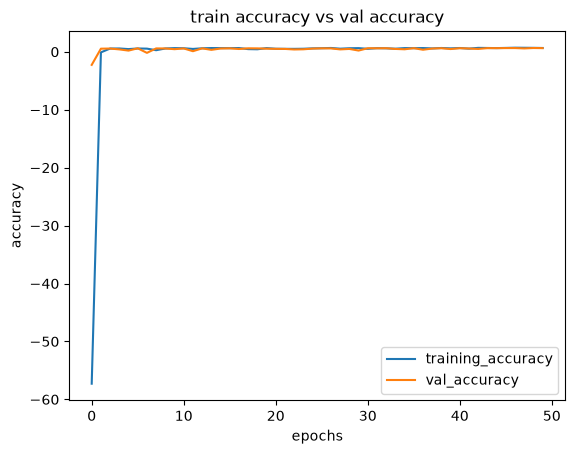

In [18]:
#plot the graphs:
plt.plot(history.history["r2_score"],label="training_accuracy")
plt.plot(history.history["val_r2_score"],label="val_accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("train accuracy vs val accuracy")
plt.legend()
plt.show()